# 02 — Corrected models and training

The saved corrected experiment is complete. Default execution reviews its recorded training; the explicit opt-in cell below runs a fresh experiment from this notebook. It never silently reuses old checkpoints for fresh pretraining.

In [1]:
from pathlib import Path
import sys, json, os
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'experiments/isolated_arsenal.py').exists())
sys.path.insert(0,str(ROOT))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'work/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, joblib
from IPython.display import display, Markdown, Image
from experiments import train
from experiments.isolated_arsenal import OUTPUT
RUN=OUTPUT
REVIEW=ROOT/'results/arsenal_isolated_review'
(REVIEW/'figures').mkdir(parents=True,exist_ok=True)
record=json.loads((RUN/'manifest.json').read_text())
for rel,digest in record['artifact_sha256'].items():
    assert train.digest(RUN/rel)==digest,rel
features=record['features']
plt.rcParams.update({'figure.figsize':(11,5),'axes.spines.top':False,'axes.spines.right':False})
def finish(name):
    plt.tight_layout(); plt.savefig(REVIEW/'figures'/f'{name}.png',dpi=110,bbox_inches='tight'); plt.show(); plt.close()
def load(population,split):
    folder=RUN/population/split
    return (pd.read_csv(folder/'X.csv').astype(np.float32),pd.read_csv(folder/'y.csv').target_result.map({'A':0,'D':1,'H':2}).to_numpy(),pd.read_csv(folder/'index.csv'))
def predict(name,x):
    if name.endswith('mlp'):
        return train.predict_checkpoint(RUN/'models'/f'{name}_best.pt',x).to_numpy()
    return joblib.load(RUN/'models'/f'{name}.joblib').predict_proba(x)
metrics=pd.read_csv(RUN/'evaluation/metrics.csv')
names=metrics.model.drop_duplicates().tolist()
# Source duplicate is a deterministic replication, excluded from model selection.
candidates=[n for n in names if n!='league_frozen_source_mlp']
validation=metrics.query("split=='validation'").set_index('model').loc[candidates]
selected=validation.log_loss.idxmin()


## Optional fresh training
Set `RUN_NEW_EXPERIMENT=True` and choose a new directory to train all seven arms. Both source fits start from scratch. Existing saved experiments are never overwritten. To review that rerun in notebooks 01–04, change their `RUN` assignment to that new directory.

In [2]:
RUN_NEW_EXPERIMENT=False
NEW_OUTPUT=ROOT/'work/arsenal_isolated_notebook_rerun'
if RUN_NEW_EXPERIMENT:
    from experiments.isolated_arsenal import run
    run(NEW_OUTPUT)
else:
    print('Reviewing completed training; no fresh fit requested.')
summary=pd.read_csv(RUN/'models/training_summary.csv');display(summary)
display(pd.Series(record['config']))
audits=pd.DataFrame([json.loads((RUN/'models'/f'{n}_execution.json').read_text()) for n in summary.model]);display(audits)

Reviewing completed training; no fresh fit requested.


,model,best_epoch,epochs_run,validation_log_loss,training_rows,checkpoint_sha256,training_population,validation_population
0,arsenal_mlp,100,100,0.864435,815,66a872e6c2b7e900069cf1e1c178b02f47494040c1f9a1...,arsenal,arsenal
1,league_mlp,99,100,0.975268,7142,103ad2f65ba73a201cc5dfe0f562310f18120450522d9d...,league,league
2,full_finetune_mlp,2,21,0.796803,815,c2a91cef3b525bb3ed0be94ba3250ad4f80c34da20500b...,arsenal,arsenal
3,league_frozen_source_mlp,99,100,0.975268,7142,f88358c991706acc5a6c81e51d9b9d7b3322256583a214...,league,league
4,head_finetune_mlp,1,20,0.797128,815,18cb0477189d6c4d6f1138509a5fdd52dce13b3db0a65e...,arsenal,arsenal


seed                                     42
max_epochs                              100
patience                                 20
min_delta                            0.0001
lr                                   0.0001
weight_decay                           0.01
batch_size                              256
hidden                             [32, 16]
dropout                                 0.1
selection       Arsenal validation log loss
threads                                   2
dtype: object

,model,freeze_hidden,trainable_parameters,started_utc,initial_checkpoint,initial_weights_sha256,initial_checkpoint_sha256,training_rows,validation_rows,optimizer_steps,frozen_hidden_layers_unchanged,finished_utc,elapsed_seconds,best_weights_sha256,best_epoch,epochs_run,stop_reason
0,arsenal_mlp,False,"[0.weight, 0.bias, 3.weight, 3.bias, 5.weight,...",2026-10-26T10:40:17.625301+00:00,None,a82b44ca3abc7438de0fbd0854c518ff90448624564e79...,None,815,74,400,False,2026-10-26T10:40:18.882460+00:00,1.267514,09e8eea1851b750f2da9bb1b27f73c1100002ebc1f3ab8...,100,100,maximum epochs
1,league_mlp,False,"[0.weight, 0.bias, 3.weight, 3.bias, 5.weight,...",2026-10-26T10:40:18.886613+00:00,None,a82b44ca3abc7438de0fbd0854c518ff90448624564e79...,None,7142,654,2800,False,2026-10-26T10:40:21.172940+00:00,2.290137,3b0bacfa2389a518e26a6e7ad8cfbe93452400e5b7d0c7...,99,100,maximum epochs
2,full_finetune_mlp,False,"[0.weight, 0.bias, 3.weight, 3.bias, 5.weight,...",2026-10-26T10:40:21.174953+00:00,/workspace/Premier-League-Research/results/ars...,3b0bacfa2389a518e26a6e7ad8cfbe93452400e5b7d0c7...,103ad2f65ba73a201cc5dfe0f562310f18120450522d9d...,815,74,84,False,2026-10-26T10:40:21.263347+00:00,0.089746,54c85f7b43a22083ff87a345846a0ea07301b3b454ffea...,2,21,patience
3,league_frozen_source_mlp,False,"[0.weight, 0.bias, 3.weight, 3.bias, 5.weight,...",2026-10-26T10:40:21.266057+00:00,None,a82b44ca3abc7438de0fbd0854c518ff90448624564e79...,None,7142,654,2800,False,2026-10-26T10:40:23.346908+00:00,2.083031,3b0bacfa2389a518e26a6e7ad8cfbe93452400e5b7d0c7...,99,100,maximum epochs
4,head_finetune_mlp,True,"[5.weight, 5.bias]",2026-10-26T10:40:23.348678+00:00,/workspace/Premier-League-Research/results/ars...,3b0bacfa2389a518e26a6e7ad8cfbe93452400e5b7d0c7...,f88358c991706acc5a6c81e51d9b9d7b3322256583a214...,815,74,80,True,2026-10-26T10:40:23.407805+00:00,0.060492,28c2651d37a4e68e61f705e31bbed30aed71b527f1dcaf...,1,20,patience


## Learning curves
Source loss curves use non-Arsenal validation; control/adaptation curves use Arsenal validation. Their validation values describe different populations and should not be ranked against each other. Online training loss includes dropout.

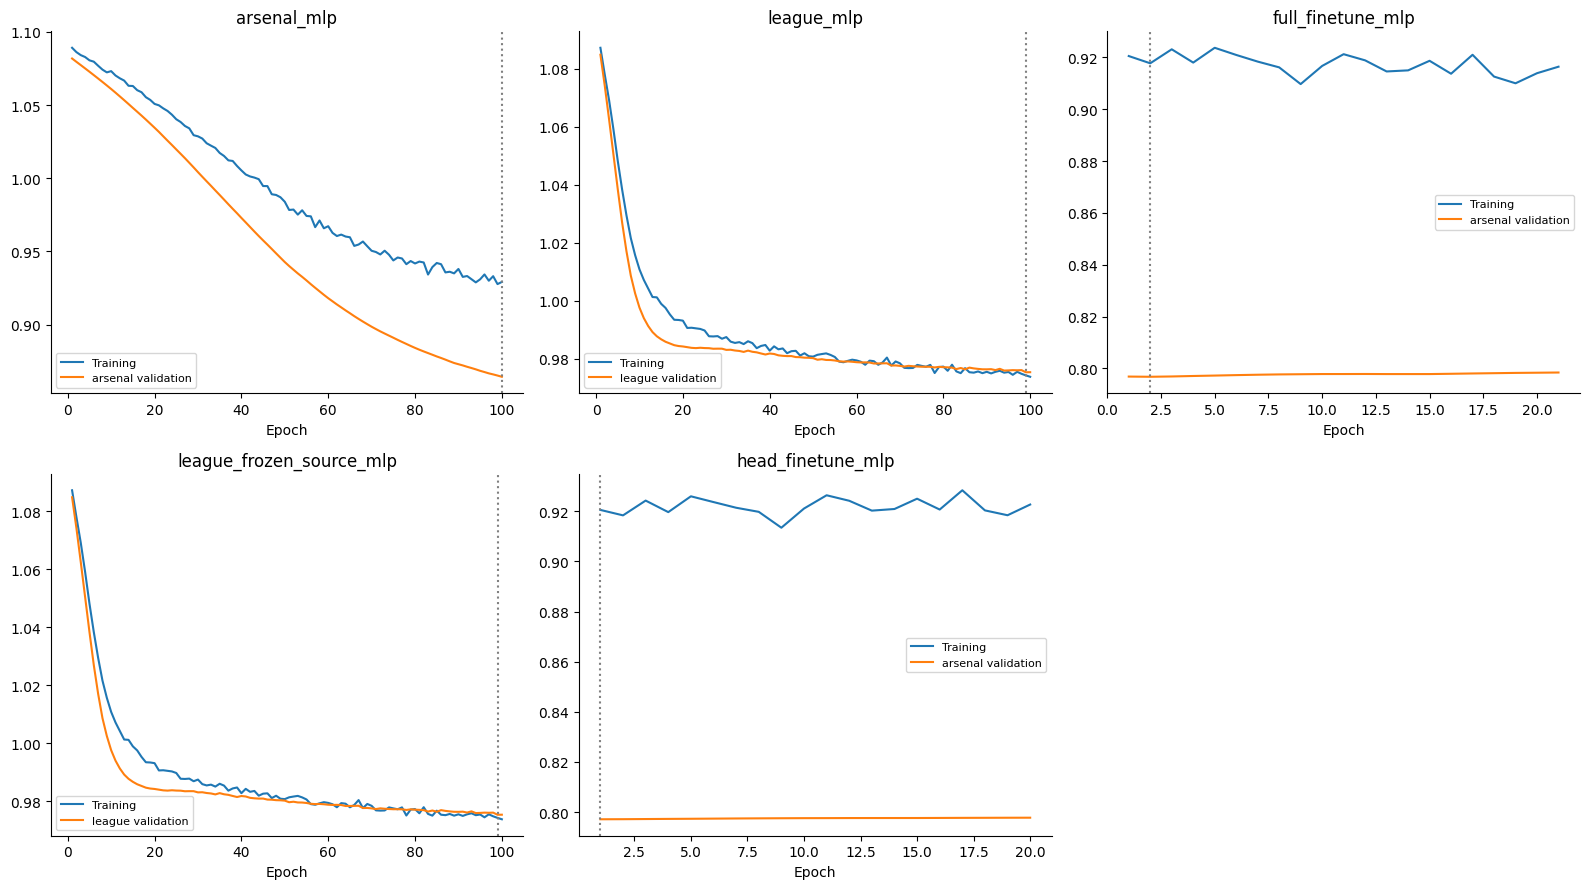

,epoch,training_log_loss,validation_log_loss,validation_accuracy,best_validation_loss,best_epoch_so_far,checkpoint_saved,patience_used,optimizer_steps,epoch_seconds,model
0,1,1.089138,1.081805,0.486486,1.081805,1,True,0,4,0.009638,arsenal_mlp
1,2,1.086166,1.079540,0.513514,1.079540,2,True,0,8,0.004442,arsenal_mlp
2,3,1.084127,1.077312,0.527027,1.077312,3,True,0,12,0.004244,arsenal_mlp
3,4,1.082826,1.075056,0.527027,1.075056,4,True,0,16,0.004061,arsenal_mlp
4,5,1.080569,1.072784,0.540541,1.072784,5,True,0,20,0.004112,arsenal_mlp
5,6,1.079655,1.070475,0.540541,1.070475,6,True,0,24,0.004179,arsenal_mlp
6,7,1.076868,1.068149,0.540541,1.068149,7,True,0,28,0.004170,arsenal_mlp
7,8,1.074225,1.065802,0.540541,1.065802,8,True,0,32,0.004129,arsenal_mlp
8,9,1.072349,1.063411,0.540541,1.063411,9,True,0,36,0.004146,arsenal_mlp
9,10,1.073181,1.060987,0.554054,1.060987,10,True,0,40,0.004220,arsenal_mlp


In [3]:
fig,axs=plt.subplots(2,3,figsize=(16,9)); histories=[]
for ax,row in zip(axs.flat,summary.itertuples()):
    h=pd.read_csv(RUN/'models'/f'{row.model}_history.csv');histories.append(h.assign(model=row.model))
    ax.plot(h.epoch,h.training_log_loss,label='Training');ax.plot(h.epoch,h.validation_log_loss,label=f'{row.validation_population} validation');ax.axvline(row.best_epoch,ls=':',color='grey');ax.set_title(row.model);ax.set_xlabel('Epoch');ax.legend(fontsize=8)
axs.flat[-1].axis('off');finish('11_learning_curves')
with pd.option_context('display.max_rows',None): display(pd.concat(histories,ignore_index=True))

In [4]:
def ck(name): return torch.load(RUN/'models'/f'{name}_best.pt',weights_only=False,map_location='cpu')
a=ck('league_frozen_source_mlp'); b=ck('head_finetune_mlp')
checks={key:torch.equal(a['model_state'][key],b['model_state'][key]) for key in ['0.weight','0.bias','3.weight','3.bias']}
assert all(checks.values())
assert audits.set_index('model').loc['head_finetune_mlp','trainable_parameters']==['5.weight','5.bias']
assert any(not torch.equal(a['model_state'][key],b['model_state'][key]) for key in ['5.weight','5.bias'])
display(pd.Series(checks,name='frozen_hidden_parameter_unchanged'))
print('Head-only adaptation changed output parameters. Both independent source fits completed with identical deterministic settings.')

0.weight    True
0.bias      True
3.weight    True
3.bias      True
Name: frozen_hidden_parameter_unchanged, dtype: bool

Head-only adaptation changed output parameters. Both independent source fits completed with identical deterministic settings.
